# Intermolecular Interactions: Day 3



In [1]:
import pandas as pd
from scipy.constants import (
    Boltzmann as k_B,
    Avogadro as N_A,
    epsilon_0,
    elementary_charge as e,
    gas_constant as R
)
import numpy as np
import matplotlib.pyplot as plt

def ion_ion(z1z2, lB, r):
    """ion-ion energy in reduced units, i.e. in units of kT"""
    return lB * z1z2 / r

## Electrostatic energy

The dipole-dipole energy is also called the _Keesom_ interaction, which comes from calculating the orientationally averaged energy between two rotating dipoles. This represents one of three $1/r^6$ of the _van der Waals interaction_.
The other two terms come from _dispersion / London forces_ and from _dipole-induced dipole_ interactions. The latter is due to a permanent dipole that induce a dipole in the other atom or molecule. This is also called the _Debye_ interaction.

Type                           | Energy, $u/k_BT$                            | Illustration
------------------------------ | ------------------------------------------- | ---------------
Monopole-monopole              | $\frac{\ell_B z_1z_2}{r}$                | $\oplus \leftrightarrow \oplus$
Ion - freely rotating dipole   | $-\frac{(\ell_B z_1 \mu_2)^2}{6r^4}$     | $\oplus \leftrightarrow \langle \nearrow \rangle$
Dipole-dipole (freely rotating)| $-\frac{ (\ell_B\mu_1\mu_2)^2 }{3r^6}$   | $\langle \nwarrow \rangle \leftrightarrow \langle \nearrow \rangle$

## Example: Two proteins

<div align="center">
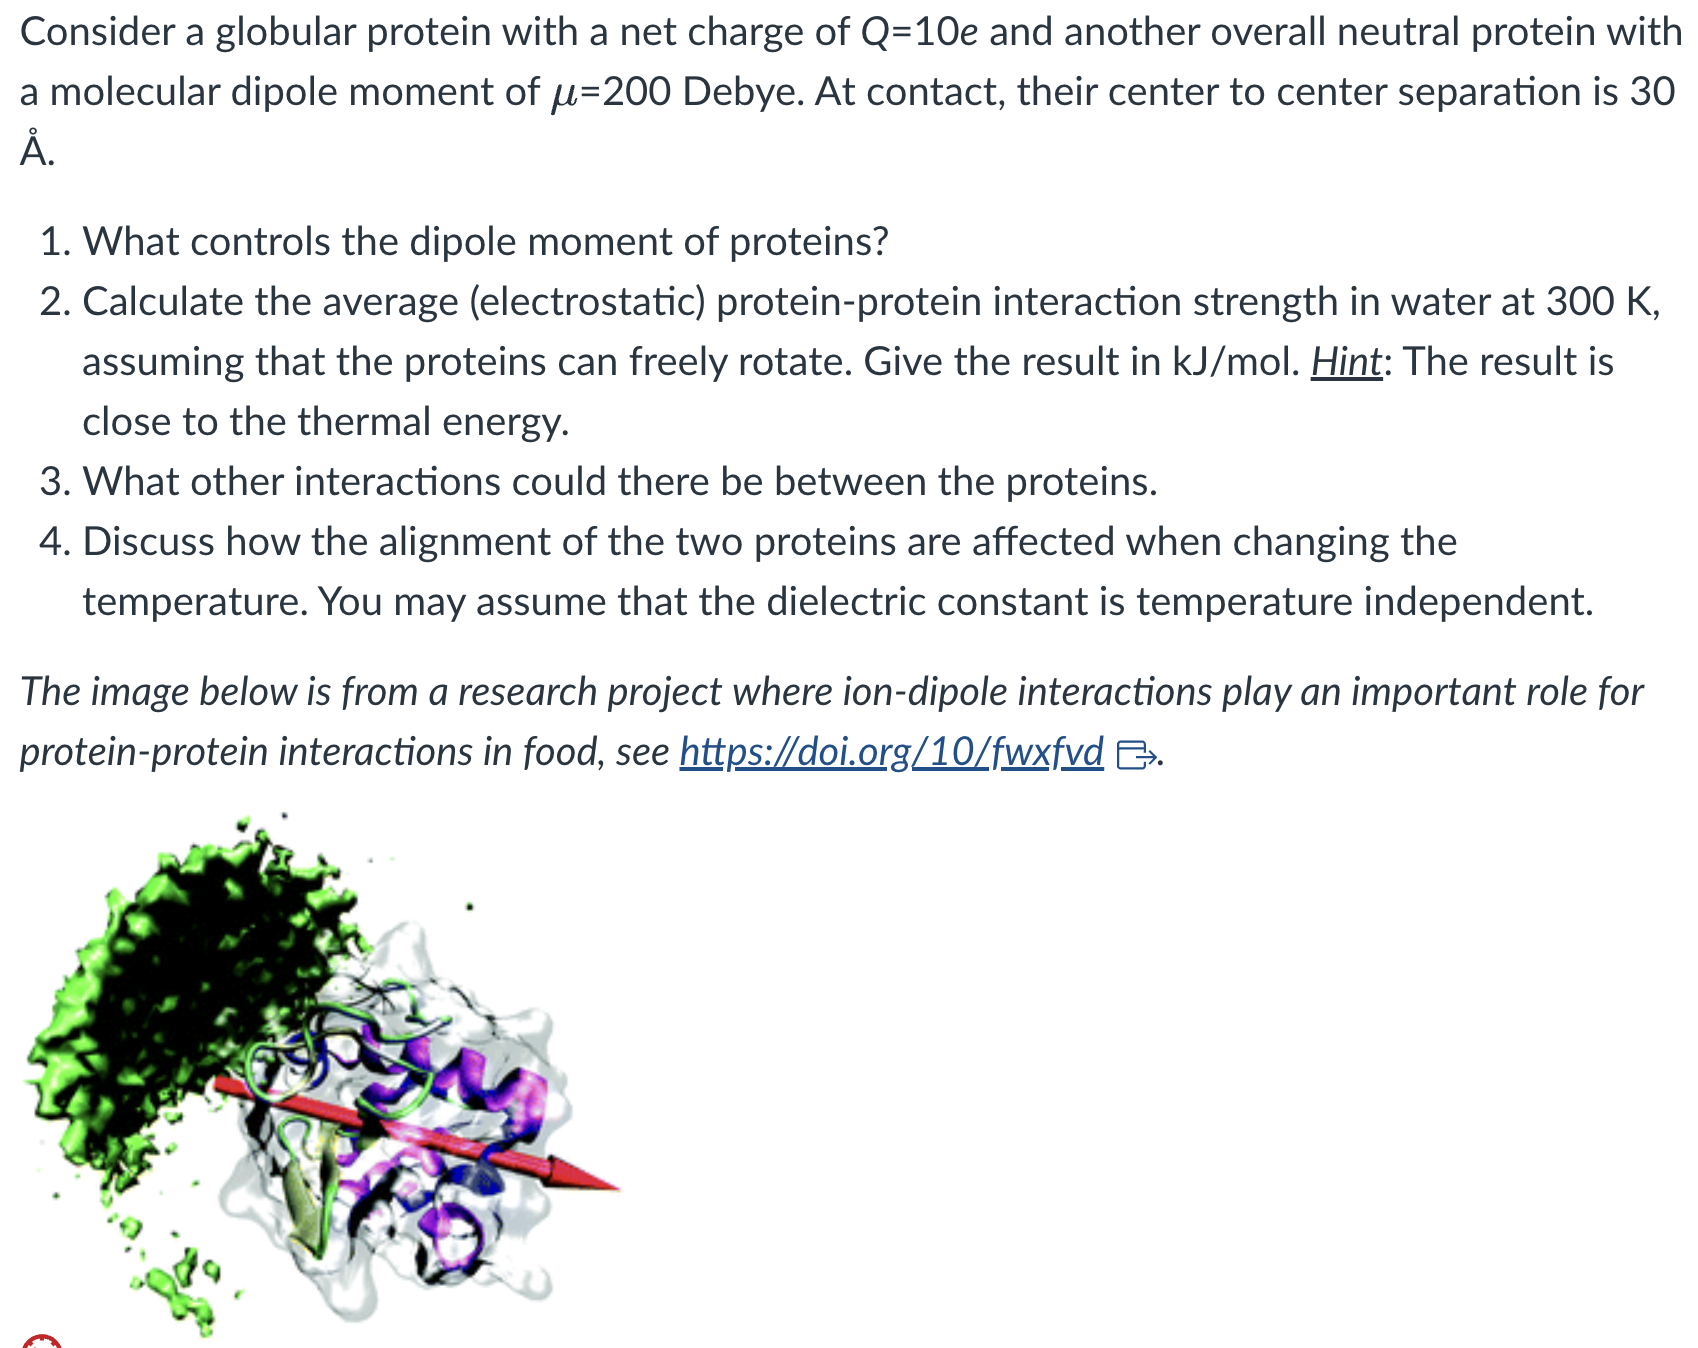
</div>

### Solution

1. The dipole moment is mainly controlled by charges residues side chains (COO-, NH3+) which varies strongly with the solution pH.
2. If the two proteins are described as an ion and a freely rotating dipole, the interaction _free energy_ is:
$$
w(R)/k_BT = -\frac{(\ell_BZ_1\mu_2)^2}{6R^4} = \frac{1}{2}\langle u(R) \rangle / k_BT
$$
which can be related to **Eq. 24.7 in Dill and Bromberg** for the average _energy_ (note the factor one half).
3. van der Waals; hydrophobic; H-bonds.
4. At high temperature, all orientations (states) are equally populated, and the electrostatic free energy goes to zero. 


In [2]:
Z = 10           # Net charge number of first protein, Z = Q/e
mu = 200 / 4.803 # Dipole moment on second protein, D -> eÅ
R = 30           # Center-center separation, Å
T = 300          # Temperature, K
epsilon_r = 80   # Relative dielectric constant of water

def bjerrum_length(T, epsilon_r):
    """Bjerrum length (Å)"""
    return e**2 / (4 * np.pi * epsilon_r * epsilon_0 * k_B * T) * 1e10

def ion_dipole_free(z, mu, lB, R):
    '''free energy between ion and freely rotating dipole (kT)'''
    return -(lB * mu * z)**2 / (6 * R**4)

def ion_dipole_free_SI(q, mu, R):
    '''free energy between ion and freely rotating dipole (J). Dill Eq. 24.7 / 2'''
    return -(mu * q / (4 * np.pi * epsilon_0 * epsilon_r) )**2 / (6 * R**4 * k_B * T)

lB = bjerrum_length(T, epsilon_r)
u = ion_dipole_free(Z, mu, lB, R)
print(f"Average protein-protein interaction energy = {u:.2f} kT")

u_si = ion_dipole_free_SI(Z * e, mu * e * 1e-10, R * 1e-10)
print("\nWe can also stick to SI units and get the same result:")
print(f"  {u_si:.2e} J = {u_si / (k_B * T):.2f} kT = {u_si * N_A / 1000:.2f} kJ/mol")

Average protein-protein interaction energy = -1.73 kT

We can also stick to SI units and get the same result:
  -7.16e-21 J = -1.73 kT = -4.31 kJ/mol


## Example: Water-water interaction in vacuum

Here you must estimate the contact distance and gas phase dipole moment of water. We here calculate the interaction free energy using reduced units, but you could also use SI.
$$
\beta w(r) = -\frac{(\ell_B\mu_1\mu_2)^2}{6r^6} = \frac{1}{2}\langle \beta u(r) \rangle\,\,\,\mbox{(see Dill Eq. 24.8)}
$$

In [7]:
from scipy.constants import (
    Boltzmann as k_B,
    Avogadro as N_A,
    epsilon_0,
    elementary_charge as e,
    gas_constant as R
)

mu = 1.85 / 4.803 # Approximate Dipole moment, D -> eÅ
r  = 3            # O-O distance in water, Å
epsilon_r = 1     # Dielectric constant of vacuum
T = 300           # Temperature, K

def bjerrum_length(T, epsilon_r):
    """Bjerrum length (Å)"""
    return e**2 / (4 * np.pi * epsilon_r * epsilon_0 * k_B * T) * 1e10

def dipole_dipole_free(mu1mu2, lB, r):
    '''Interaction free energy between two freely rotating dipoles in kT, see Dill Eq. 24.8'''
    return -(mu1mu2 * lB)**2 / (3 * r**6)

lB = bjerrum_length(T, epsilon_r)
u = dipole_dipole_free(mu * mu, lB, r)

print(f"Average dipole-dipole energy = {u:.2f} kT = {u * R * T / 1000:.2f} kJ/mol")

Average dipole-dipole energy = -3.12 kT = -7.79 kJ/mol
